# Artificial Neural Networks (AIC 380)
**Student Name:** Abdullah Ghaffar  
**Registration No:** FA23-BAI-059  

---
## Lab 03: Implementation and Training of Perceptron using Learning Rule

### Objective:
Understanding and implementing the Single Layer Perceptron from scratch in Python: delta learning rule, bias trick, training on linearly separable datasets (OR gate, Iris Setosa vs Versicolor) and observing failure on non-linear datasets (XOR gate).


### Concept Implementation: Modular Perceptron Class with Delta Rule


In [1]:
import numpy as np
import matplotlib.pyplot as plt

class Perceptron:
    def __init__(self, N, alpha=0.1):
        # Initialize weight matrix with random normal values scaled by 1/sqrt(N)
        # N features + 1 for bias
        self.W = np.random.randn(N + 1) / np.sqrt(N)
        self.alpha = alpha

    def step(self, x):
        # Activation function: 1 if positive, else 0
        return 1 if x > 0 else 0

    def fit(self, X, y, epochs=10):
        # Insert column of ones for bias trick
        X = np.c_[X, np.ones((X.shape[0]))]
        loss_history = []

        for epoch in range(epochs):
            misclassified = 0
            for (x, target) in zip(X, y):
                p = self.step(np.dot(x, self.W))
                if p != target:
                    error = target - p
                    self.W += self.alpha * error * x
                    misclassified += 1
            loss_history.append(misclassified)
        return loss_history

    def predict(self, X, addBias=True):
        X = np.atleast_2d(X)
        if addBias:
            X = np.c_[X, np.ones((X.shape[0]))]
        preds = [self.step(np.dot(x, self.W)) for x in X]
        return np.array(preds)

print("Perceptron class defined successfully.")


Perceptron class defined successfully.


### Evaluation 1: Bitwise OR Gate (Linearly Separable)


In [2]:
# OR Dataset
X_or = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_or = np.array([0, 1, 1, 1])

p_or = Perceptron(N=2, alpha=0.1)
loss_or = p_or.fit(X_or, y_or, epochs=20)

print("[INFO] Testing trained Perceptron on OR Gate:")
for (x, target) in zip(X_or, y_or):
    pred = p_or.predict(x)[0]
    print(f"Input: {x}, Ground-truth: {target}, Predicted: {pred}")

print(f"Final Weights: {p_or.W}")


[INFO] Testing trained Perceptron on OR Gate:
Input: [0 0], Ground-truth: 0, Predicted: 0
Input: [0 1], Ground-truth: 1, Predicted: 1
Input: [1 0], Ground-truth: 1, Predicted: 1
Input: [1 1], Ground-truth: 1, Predicted: 1
Final Weights: [ 0.31241229  0.48315096 -0.17769489]


### Evaluation 2: Bitwise XOR Gate (Non-linearly Separable)


In [3]:
# XOR Dataset
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_xor = np.array([0, 1, 1, 0])

p_xor = Perceptron(N=2, alpha=0.1)
loss_xor = p_xor.fit(X_xor, y_xor, epochs=20)

print("[INFO] Testing trained Perceptron on XOR Gate:")
for (x, target) in zip(X_xor, y_xor):
    pred = p_xor.predict(x)[0]
    print(f"Input: {x}, Ground-truth: {target}, Predicted: {pred}")
print("Notice how XOR fails because a single line cannot separate (0,0) and (1,1) from (0,1) and (1,0).")


[INFO] Testing trained Perceptron on XOR Gate:
Input: [0 0], Ground-truth: 0, Predicted: 1
Input: [0 1], Ground-truth: 1, Predicted: 0
Input: [1 0], Ground-truth: 1, Predicted: 0
Input: [1 1], Ground-truth: 0, Predicted: 0
Notice how XOR fails because a single line cannot separate (0,0) and (1,1) from (0,1) and (1,0).


### Activity 1: Loading & Visualizing Iris Dataset


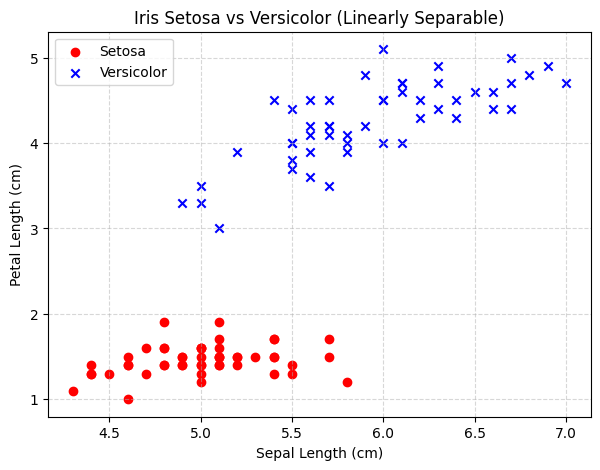

In [4]:
from sklearn.datasets import load_iris
import pandas as pd

# Load Iris from sklearn for reliable offline reproducibility
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['target'] = iris.target
df['species'] = df['target'].map({0: 'Iris-setosa', 1: 'Iris-versicolor', 2: 'Iris-virginica'})

# Filter to only first 100 samples (setosa vs versicolor)
df_binary = df[df['target'] < 2].copy()
X_iris = df_binary.iloc[:, [0, 2]].values  # sepal length & petal length
y_iris = df_binary['target'].values

plt.figure(figsize=(7, 5))
plt.scatter(X_iris[:50, 0], X_iris[:50, 1], color='red', marker='o', label='Setosa')
plt.scatter(X_iris[50:100, 0], X_iris[50:100, 1], color='blue', marker='x', label='Versicolor')
plt.xlabel('Sepal Length (cm)')
plt.ylabel('Petal Length (cm)')
plt.title('Iris Setosa vs Versicolor (Linearly Separable)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


### Activity 2: Training Perceptron on Iris & Plotting Misclassification Curve


Learned Weights [bias, w_sepal_length, w_petal_length]: [-0.2  -0.35  0.92]


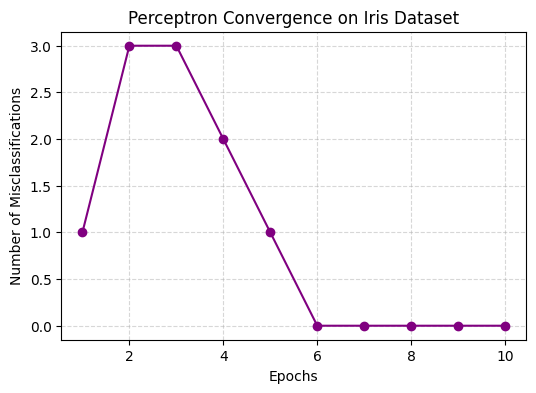

In [5]:
# Manual Perceptron implementation matching manual code
def perceptron_train(X, y, num_iter=10, alpha=0.1):
    w = np.zeros(X.shape[1] + 1)
    misclassified_history = []

    for epoch in range(num_iter):
        misclassified = 0
        for xi, target in zip(X, y):
            xi_bias = np.insert(xi, 0, 1.0)
            y_pred = 1.0 if np.dot(w, xi_bias) > 0.0 else 0.0
            delta = target - y_pred
            if delta != 0.0:
                misclassified += 1
                w += alpha * delta * xi_bias
        misclassified_history.append(misclassified)
    return w, misclassified_history

weights, errors = perceptron_train(X_iris, y_iris, num_iter=10, alpha=0.1)

print("Learned Weights [bias, w_sepal_length, w_petal_length]:", weights)

plt.figure(figsize=(6, 4))
plt.plot(range(1, len(errors) + 1), errors, marker='o', color='purple')
plt.xlabel('Epochs')
plt.ylabel('Number of Misclassifications')
plt.title('Perceptron Convergence on Iris Dataset')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


### Graded Lab Tasks 1 & 2: UCI/Kaggle Dataset Training, Learning Curve & Decision Boundary


Trained Perceptron Weights: [-0.02558108 -0.00639001 -0.00822299]
Test Set Accuracy: 83.92%


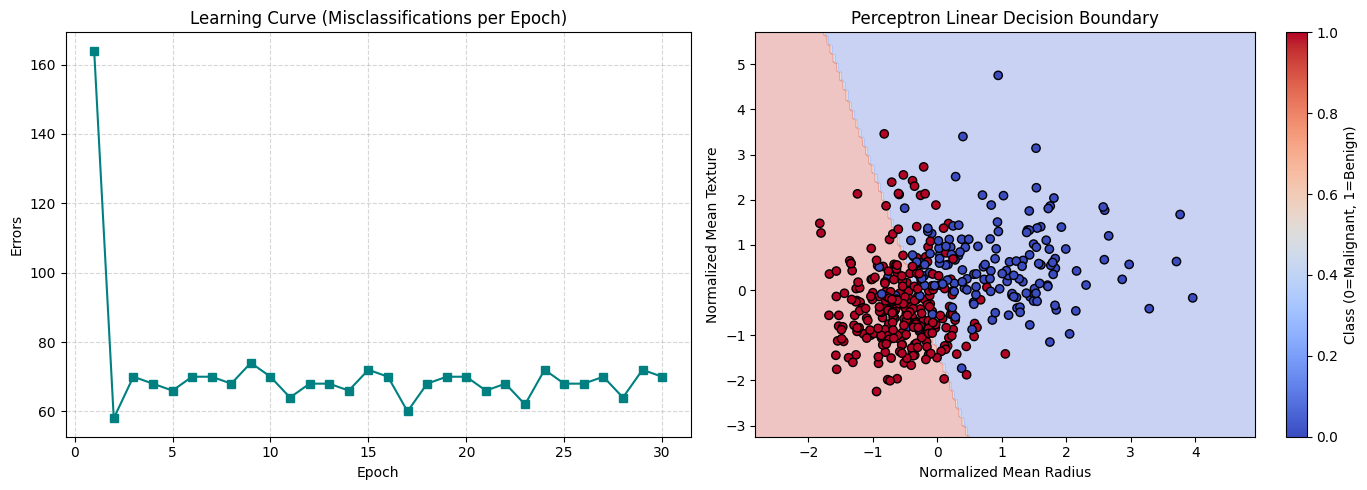

In [6]:
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Task 1: Load dataset and select linearly separable feature pair
cancer = load_breast_cancer()
# Select 2 features: mean radius and mean texture
X_cancer = cancer.data[:, :2]
y_cancer = cancer.target  # 0: Malignant, 1: Benign

X_train, X_test, y_train, y_test = train_test_split(X_cancer, y_cancer, test_size=0.25, random_state=42)

scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.transform(X_test)

# Task 2: Implement & Train Perceptron
p_cancer = Perceptron(N=2, alpha=0.01)
epochs = 30
loss_curve = p_cancer.fit(X_train_std, y_train, epochs=epochs)

# Evaluate on test set
preds = p_cancer.predict(X_test_std)
accuracy = np.mean(preds == y_test)
print(f"Trained Perceptron Weights: {p_cancer.W}")
print(f"Test Set Accuracy: {accuracy * 100:.2f}%")

# Plot Learning Curve
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(range(1, epochs + 1), loss_curve, marker='s', color='teal')
ax[0].set_title('Learning Curve (Misclassifications per Epoch)')
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Errors')
ax[0].grid(True, linestyle='--', alpha=0.5)

# Plot Decision Boundary
x_min, x_max = X_train_std[:, 0].min() - 1, X_train_std[:, 0].max() + 1
y_min, y_max = X_train_std[:, 1].min() - 1, X_train_std[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05), np.arange(y_min, y_max, 0.05))
grid_points = np.c_[xx.ravel(), yy.ravel()]
Z = p_cancer.predict(grid_points).reshape(xx.shape)

ax[1].contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
scatter = ax[1].scatter(X_train_std[:, 0], X_train_std[:, 1], c=y_train, cmap=plt.cm.coolwarm, edgecolors='k')
ax[1].set_title('Perceptron Linear Decision Boundary')
ax[1].set_xlabel('Normalized Mean Radius')
ax[1].set_ylabel('Normalized Mean Texture')
plt.colorbar(scatter, ax=ax[1], label='Class (0=Malignant, 1=Benign)')
plt.tight_layout()
plt.show()
